# Trash Sorting by Material: Hand-Designed Features vs. a Small CNN vs. a Pretrained Mobile Model
**Computer Vision Group Project - West Visayas State University**

**Task:** image classification. Given a photo of one piece of trash, predict its material:
`cardboard, glass, metal, paper, plastic, trash` (residual).

| Slot | Method | Implementation |
|---|---|---|
| A. Classical | HOG + linear SVM | HOG **and** the SVM written from scratch in NumPy (`src/hog_svm.py`) |
| B. Trained from scratch | Our 4-block CNN | Designed and written in PyTorch, random init (`src/scratch_cnn.py`) |
| C. Pretrained, modern | MobileNetV3-Large (2019) | torchvision ImageNet weights, fine-tuned (`src/pretrained_mobilenet.py`) |

**Research question:** *Which method best sorts trash by material, and does it still work on messy
real-world photos after training on clean studio ones?*

All three methods use **the same saved split** (`splits/split.json`), the **same metric code**
(`src/common.py`) and the **same timing protocol** (CPU, batch size 1, warm-up, mean over 200 images).

**How to run in Google Colab:** open this notebook from GitHub (the first cell clones the repository; or upload `GroupNo_CVProject.zip` to *My Drive* and set `GIT_URL = ""`),
choose *Runtime -> Change runtime type -> GPU*, then *Runtime -> Run all*.
A full run from scratch (all six experiments) takes roughly one hour on a Colab T4 GPU.

In [1]:
# ---- 0. Setup: locate the project (local or Colab) ----------------------------------------
import os, sys, subprocess, time, json
from pathlib import Path

RETRAIN = False          # True = retrain every model even if saved models exist
GIT_URL = "https://github.com/karlsxo/Computer-Vison---Final-Project.git"   # project repository (Colab clones it); set "" to use the zip on Drive
ZIP_ON_DRIVE = "/content/drive/MyDrive/GroupNo_CVProject.zip"

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    PROJECT = Path("/content/project")
    if not (PROJECT / "src").exists():
        if GIT_URL:
            subprocess.run(["git", "clone", GIT_URL, str(PROJECT)], check=True)
        else:
            from google.colab import drive
            drive.mount("/content/drive")
            subprocess.run(["unzip", "-q", "-o", ZIP_ON_DRIVE, "-d", "/content/unzipped"], check=True)
            src = next(Path("/content/unzipped").rglob("src")).parent
            subprocess.run(["cp", "-r", str(src), str(PROJECT)], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", str(PROJECT / "requirements.txt")])
else:
    PROJECT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(PROJECT)
sys.path.insert(0, str(PROJECT / "src"))
print("Project folder:", PROJECT, "| Colab:", IN_COLAB)

Project folder: C:\Users\user\Documents\Projects\Computer Vision | Colab: False


In [2]:
# ---- 0b. Download the datasets if they are not present ------------------------------------
import urllib.request, zipfile
RAW = PROJECT / "data" / "raw"; RAW.mkdir(parents=True, exist_ok=True)
SOURCES = {
    # TrashNet (Thung & Yang, 2016) - 2,527 images, 6 classes, 512x384
    "dataset-resized": "https://github.com/garythung/trashnet/raw/master/data/dataset-resized.zip",
    # 12-class web-scraped Garbage Classification dataset (Kaggle, mirrored on Hugging Face)
    "garbage12": "https://huggingface.co/datasets/UdaraChamidu/Garbage-Classification-with-12-classes/resolve/main/garbage_classification.zip",
}
for name, url in SOURCES.items():
    target = RAW / name
    if target.exists():
        print(f"{name}: present"); continue
    zpath = RAW / f"{name}.zip"
    print(f"Downloading {name} ..."); urllib.request.urlretrieve(url, zpath)
    with zipfile.ZipFile(zpath) as z:
        z.extractall(RAW if name == "dataset-resized" else target)
    print(f"{name}: extracted")

dataset-resized: present
garbage12: present


In [3]:
# ---- 0c. Imports, versions, seeds ---------------------------------------------------------
import torch_common as tc          # probes CUDA first (falls back to CPU if the GPU is unusable)
import numpy as np, torch, torchvision, platform, matplotlib
import matplotlib.pyplot as plt
from IPython.display import Image as ShowImage, Markdown, display
from common import *
set_seed(SEED)
print(f"python {platform.python_version()} | numpy {np.__version__} | torch {torch.__version__} | "
      f"torchvision {torchvision.__version__} | device: {tc.DEVICE}")
if torch.cuda.is_available(): print("GPU:", torch.cuda.get_device_name(0))
def show(name, width=1000): display(ShowImage(filename=str(FIG_DIR / name), width=width))
def need(path): return RETRAIN or not Path(path).exists()

python 3.14.6 | numpy 2.5.4 | torch 2.14.1+cu126 | torchvision 0.29.1+cu126 | device: cpu


## 1. Data: cleaning and a leakage-safe split

* **Exact duplicates:** identical files (MD5). Three files appear under *two different classes*
  (e.g. `glass176.jpg` = `plastic152.jpg`) - the label is ambiguous, so every copy is dropped.
* **Near-duplicates:** TrashNet often contains the same item photographed twice. We compute a
  *detail signature* (64x64 grayscale minus a heavy blur, which removes the shared studio lighting,
  then zero-mean/unit-norm) and link pairs whose correlation exceeds 0.80. Linked images form a
  *group* and a group always goes to one split, so the same item never appears in train and test.
  (A 64-bit dHash was tried first and rejected: on plain backgrounds it linked 1,053 pairs of
  *different-class* images.)
* **Split:** seeded, stratified, group-aware 70/15/15, saved to `splits/split.json` and loaded by all methods.
* **Real-world test set (domain shift):** 100 images/class from the web-scraped 12-class Garbage
  Classification dataset (the three glass classes -> glass; battery, biological, clothes, shoes excluded).
  490 of its images turned out to be copies of TrashNet images and were excluded.

In [4]:
import prepare_data
if need(SPLIT_FILE) or need(REALWORLD_FILE):
    sigs = prepare_data.build_trashnet_split()
    prepare_data.build_realworld(sigs)
js = load_json(SPLIT_FILE)
print(json.dumps({k: v for k, v in js["stats"].items() if k != "counts"}, indent=1))
import pandas as pd
display(pd.DataFrame(js["stats"]["counts"]).assign(total=lambda d: d.sum(1)))
print("Real-world set:", len(load_realworld()), "images; own photos:", len(own_photo_items()))

{
 "found": 2527,
 "exact_duplicates_removed": 0,
 "label_conflicts_dropped": 6,
 "near_duplicate_pairs": 30,
 "cross_class_pairs": 1,
 "groups": 2490,
 "multi_image_groups": 29,
 "dropped_mixed_label": 2,
 "max_similarity_hist": {
  ">0.5": 419,
  ">0.6": 184,
  ">0.7": 89,
  ">0.8": 60,
  ">0.9": 46,
  ">0.95": 40
 }
}


,train,val,test,total
cardboard,282,61,60,403
glass,348,75,74,497
metal,286,61,61,408
paper,416,89,89,594
plastic,336,72,72,480
trash,96,21,20,137


Real-world set: 600 images; own photos: 0


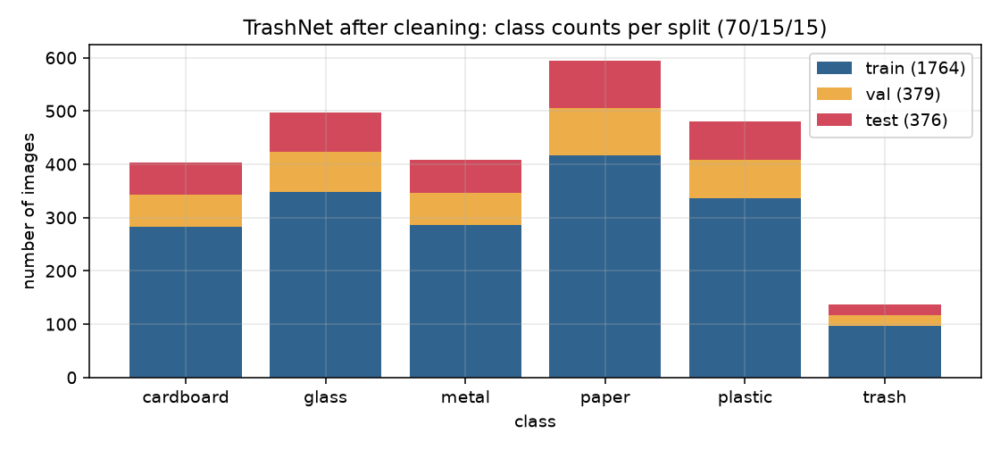

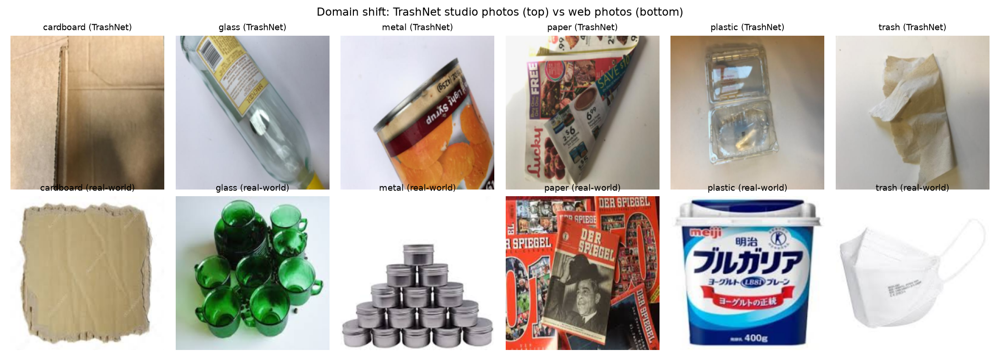

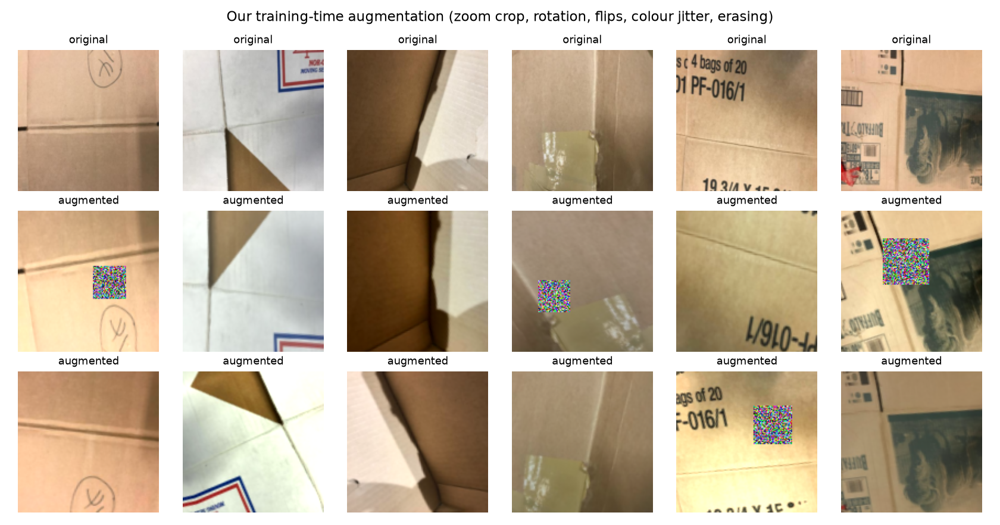

In [5]:
import experiments as E
E.dataset_figures()
show("data_class_counts.png", 700); show("data_domain_examples.png"); show("data_augmentation.png", 900)

## 2. Method A - HOG + linear SVM (classical, written from scratch)

**HOG (Dalal & Triggs, 2005)** - our NumPy implementation (`src/hog_svm.py`):
1. grayscale (BT.601), gradients with the `[-1, 0, 1]` kernel, magnitude and unsigned orientation (0-180 deg);
2. 8x8-pixel cells, 9-bin orientation histograms weighted by magnitude (linear interpolation between bins);
3. overlapping 2x2-cell blocks, L2-Hys normalisation (clip at 0.2); concatenation -> 8,100-D vector (128x128 input).

**Linear SVM** - one-vs-rest, L2-regularised squared hinge loss (the L2-loss SVM of LIBLINEAR),
class-balanced weights, optimised by our own full-batch Adam with cosine learning-rate decay.
Features are standardised with training-set statistics. Hyper-parameters (cell size, soft/hard
binning, regularisation lambda) are chosen on the **validation** split.

**Sanity checks:** (a) synthetic bars/edges must peak in the expected orientation bin;
(b) our HOG must match scikit-image's reference HOG; (c) our SVM must separate a toy dataset.

(a) vertical bar    expected    0 deg -> peak bin (0.0, 20.0)  pass=True
(a) horizontal bar  expected   90 deg -> peak bin (80.0, 100.0)  pass=True
(a) diagonal edge   expected   45 deg -> peak bin (40.0, 60.0)  pass=True
(b) vs scikit-image: {'max_abs_diff': 1.0485703799689716e-07, 'min_correlation': 0.9999999999999972, 'n_images': 8, 'pass': True}
(c) toy SVM: {'train_accuracy': 100.0, 'pass': True}


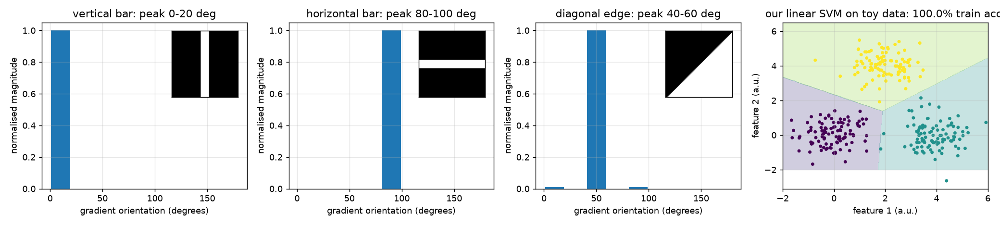

In [6]:
import hog_svm as A
sc = A.sanity_checks()
for name, t in sc["synthetic"].items():
    print(f"(a) {name:<15} expected {t['expected_deg']:>4.0f} deg -> peak bin {t['peak_range_deg']}  pass={t['pass']}")
print("(b) vs scikit-image:", sc["skimage_reference"])
print("(c) toy SVM:", sc["toy_svm"])
show("A_sanity_checks.png")

In [7]:
if need(RESULTS_DIR / "method_A.json"):
    A.main()
rA = load_json(RESULTS_DIR / "method_A.json")
display(pd.DataFrame([{**r["cfg"], "lambda": r["lam"], "val_acc": round(r["val_acc"], 1),
                       "val_macro_F1": round(r["val_macro_f1"], 3)} for r in rA["tuning_log"]]))
print("Selected:", rA["selected"]["cfg"], "lambda =", rA["selected"]["lam"])
print(f"TEST accuracy {rA['test']['accuracy']:.2f}%  macro-F1 {rA['test']['macro_f1']:.3f}  "
      f"runtime {rA['runtime_ms_cpu']:.2f} ms/img (CPU)  train {rA['train_time_min']:.2f} min")
v = rA["variant_color"]
print(f"Variant HOG + HSV colour histogram: TEST accuracy {v['test']['accuracy']:.2f}%  macro-F1 {v['test']['macro_f1']:.3f}")

,cell,block,nbins,soft,color,lambda,val_acc,val_macro_F1
0,8,2,9,True,False,1.0,54.1,0.536
1,8,2,9,True,False,3.0,57.0,0.553
2,8,2,9,True,False,10.0,60.2,0.589
3,8,2,9,True,False,30.0,61.5,0.590
4,8,2,9,True,False,100.0,56.7,0.536
5,8,2,9,False,False,1.0,53.3,0.509
6,8,2,9,False,False,3.0,57.5,0.563
7,8,2,9,False,False,10.0,59.9,0.583
8,8,2,9,False,False,30.0,59.6,0.569
9,8,2,9,False,False,100.0,54.9,0.520


Selected: {'cell': 8, 'block': 2, 'nbins': 9, 'soft': True, 'color': False} lambda = 30.0
TEST accuracy 52.93%  macro-F1 0.519  runtime 3.57 ms/img (CPU)  train 0.31 min
Variant HOG + HSV colour histogram: TEST accuracy 59.57%  macro-F1 0.587


## 3. Method B - our 4-block CNN, trained from scratch

```
input 3x128x128
Block 1: Conv3x3(3->32)   BN ReLU                      MaxPool -> 32x64x64
Block 2: Conv3x3(32->64)  BN ReLU                      MaxPool -> 64x32x32
Block 3: Conv3x3(64->128) BN ReLU Conv3x3(128->128) BN ReLU MaxPool -> 128x16x16
Block 4: Conv3x3(128->256)BN ReLU Conv3x3(256->256) BN ReLU MaxPool -> 256x8x8
GlobalAvgPool -> Dropout(0.4) -> Linear(256->6)          (1.13 M parameters, He init)
```
**Training:** class-weighted cross-entropy with label smoothing 0.1, AdamW (lr 2e-3, weight decay 0.05),
3-epoch warm-up + cosine decay, batch 32, up to 45 epochs.
**Overfitting controls:** our per-image augmentation (random zoom-crop 50-100 %, rotation +-25 deg,
horizontal/vertical flips, colour jitter, random erasing), dropout, weight decay, label smoothing,
early stopping on validation macro-F1 (best checkpoint restored).

In [8]:
import scratch_cnn as B
print(B.build_model()); print(f"parameters: {tc.count_params(B.build_model()):.3f} M")
if need(RESULTS_DIR / "method_B.json"):
    B.main()
rB = load_json(RESULTS_DIR / "method_B.json")
print(f"best epoch {rB['train_info']['best_epoch']} of {rB['train_info']['epochs_run']} | "
      f"TEST accuracy {rB['test']['accuracy']:.2f}%  macro-F1 {rB['test']['macro_f1']:.3f}  "
      f"runtime {rB['runtime_ms_cpu']:.2f} ms/img (CPU)  train {rB['train_time_min']:.1f} min on {rB['train_device']}")

TrashCNN(
  (features): Sequential(
    (0): Sequential(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (1): Sequential(
      (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (2): Sequential(
      (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Conv2d(128, 128, kernel_size=(3, 3), strid

## 4. Method C - MobileNetV3-Large, ImageNet-pretrained and fine-tuned

* Weights `IMAGENET1K_V2` from torchvision (Howard et al., *Searching for MobileNetV3*, ICCV 2019).
* The 1000-class output layer is replaced by a 6-class layer (same output format as A and B).
* Correct preprocessing: 224x224 input normalised with the ImageNet mean/std.
* Stage 1: train only the classifier head for 3 epochs (backbone frozen).
  Stage 2: fine-tune at lr 5e-4 (AdamW, cosine) for up to 12 epochs with early stopping.
  The stem and first three blocks stay frozen with BatchNorm in eval mode (generic low-level filters).
* Same split, augmentation function, loss and early-stopping rule as Method B.

In [9]:
import pretrained_mobilenet as C
if need(RESULTS_DIR / "method_C.json"):
    C.main()
rC = load_json(RESULTS_DIR / "method_C.json")
print(f"params {rC['params_M']:.2f} M (trainable {rC['trainable_params_M']:.2f} M) | best epoch "
      f"{rC['train_info']['best_epoch']} | TEST accuracy {rC['test']['accuracy']:.2f}%  macro-F1 "
      f"{rC['test']['macro_f1']:.3f}  runtime {rC['runtime_ms_cpu']:.2f} ms/img (CPU)  "
      f"train {rC['train_time_min']:.1f} min on {rC['train_device']}")

params 4.21 M (trainable 4.20 M) | best epoch 9 | TEST accuracy 92.82%  macro-F1 0.926  runtime 29.07 ms/img (CPU)  train 44.8 min on cpu


## 5. Experiment 1 - main comparison on the held-out test split


=== Experiment 1: main comparison on the TrashNet test split ===


  HOG + linear SVM                       acc  52.93% [47.6, 58.0]  macro-F1 0.5187


  4-block CNN (scratch)                  acc  71.28% [66.5, 75.8]  macro-F1 0.6943


  MobileNetV3-Large (pretrained)         acc  92.82% [90.2, 95.2]  macro-F1 0.9261


  HOG + colour hist. + SVM (variant)     acc  59.57% [54.8, 64.6]  macro-F1 0.5867


  McNemar C_vs_B: p = 1.70e-17
  McNemar C_vs_A: p = 8.13e-39
  McNemar B_vs_A: p = 8.60e-09
  McNemar A+_vs_A: p = 4.63e-03


| Method | Slot | Top-1 acc. (%) [95% CI] | Macro F1 | Runtime (ms/img, CPU) | Params (M) | Train time (min) |
|---|---|---|---|---|---|---|
| HOG + linear SVM | A. Classical | 52.9 [47.6-58.0] | 0.519 | 3.6 | 0.00 | 0.3 |
| 4-block CNN (scratch) | B. From scratch | 71.3 [66.5-75.8] | 0.694 | 16.8 | 1.13 | 100.8 |
| MobileNetV3-Large (pretrained) | C. Pretrained | 92.8 [90.2-95.2] | 0.926 | 29.1 | 4.21 | 44.8 |
| HOG + colour hist. + SVM (variant) | A. (variant) | 59.6 [54.8-64.6] | 0.587 | 13.6 | 0.00 | 0.5 |


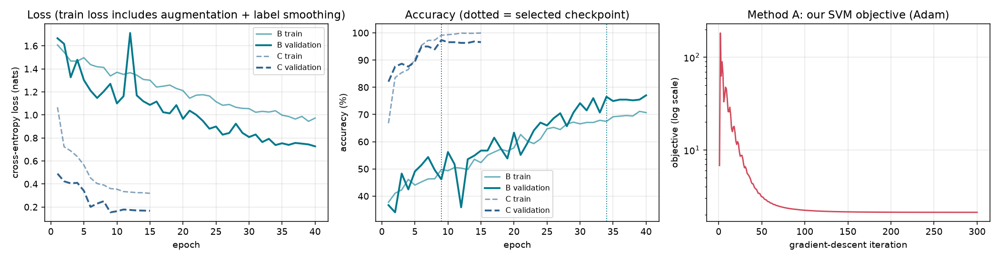

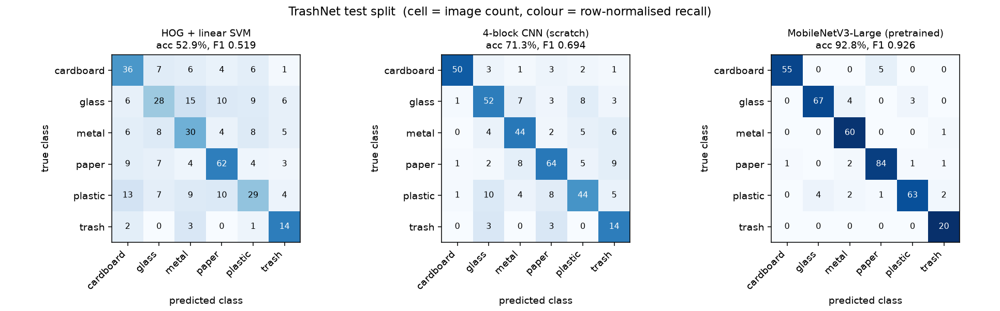

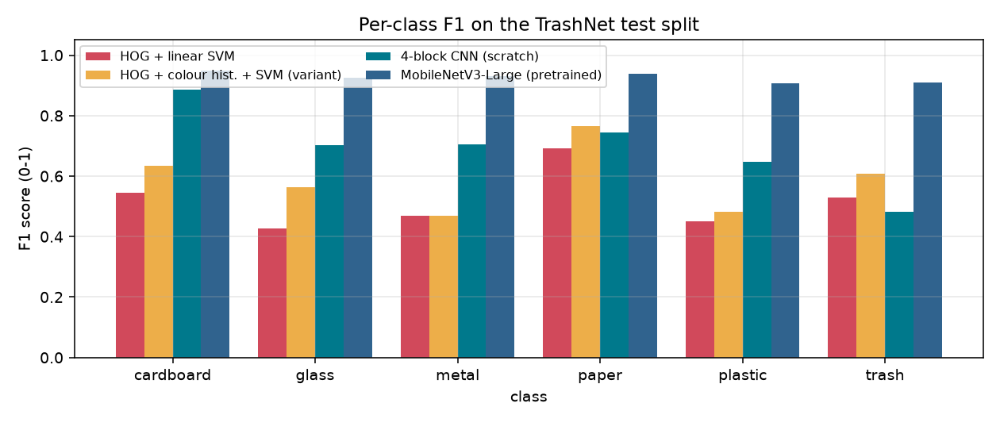

,only_first_correct,only_second_correct,p_value
C_vs_B,91.0,10.0,1.697748e-17
C_vs_A,156.0,6.0,8.129418e-39
B_vs_A,107.0,38.0,8.595663e-09
A+_vs_A,49.0,24.0,4.626294e-03


In [10]:
e1 = E.exp1_main()
display(Markdown((RESULTS_DIR / "results_table.md").read_text()))
show("exp1_training_curves.png"); show("exp1_confusion_matrices.png"); show("exp1_per_class_f1.png", 800)
display(pd.DataFrame(e1["mcnemar"]).T)

## 6. Experiment 2 - domain shift: studio photos -> real-world web photos


=== Experiment 2: domain shift (studio -> real-world web photos) ===


  [realworld] HOG + linear SVM                       acc   9.33%  F1 0.084  (drop +43.6 pts)
  [realworld] HOG + colour hist. + SVM (variant)     acc  16.50%  F1 0.152  (drop +43.1 pts)
  [realworld] 4-block CNN (scratch)                  acc  36.17%  F1 0.326  (drop +35.1 pts)


  [realworld] MobileNetV3-Large (pretrained)         acc  62.83%  F1 0.582  (drop +30.0 pts)


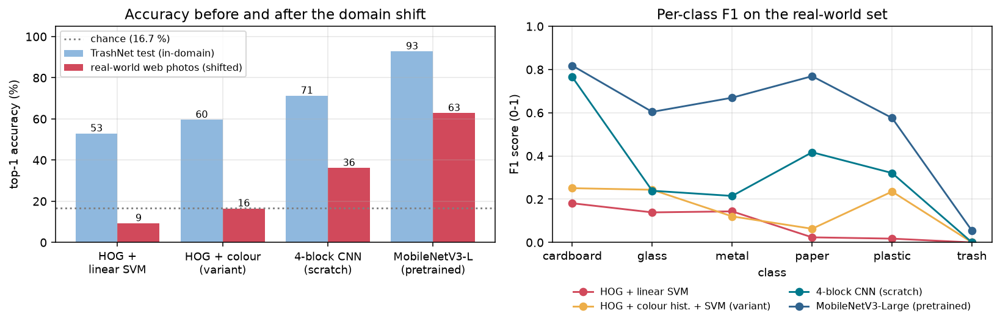

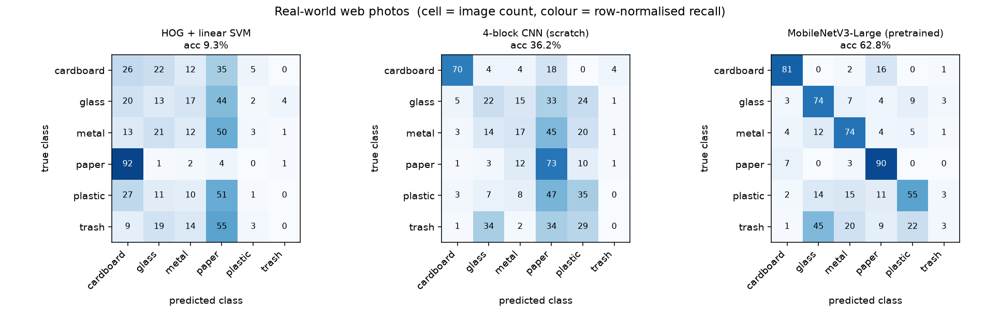

In [11]:
models = E.load_models()
e2 = E.exp2_domain_shift(models)
show("exp2_domain_shift.png"); show("exp2_confusion_realworld.png")

## 7. Experiment 3 - small data (10, 25, 50 images per class)
Each method is retrained on a seeded per-class subsample of the training split, with the same
validation split for model selection and the same test split for scoring. The classical method
re-tunes lambda; the networks use a fixed number of optimisation steps (B ~500, C ~150 + head).


=== Experiment 3: small-data regime ===


,method,n_per_class,n_train,accuracy,macro_f1,train_time_min
A_10,A,10,60,36.702128,0.356952,0.051918
B_10,B,10,60,43.351064,0.429874,15.695095
C_10,C,10,60,67.553191,0.662693,11.935668
A_25,A,25,150,35.37234,0.357766,0.069258
B_25,B,25,150,58.776596,0.578384,15.633044
C_25,C,25,150,75.531915,0.734265,13.257676
A_50,A,50,300,40.957447,0.409083,0.14253
B_50,B,50,300,61.43617,0.59883,15.159548
C_50,C,50,300,83.776596,0.819156,14.321468


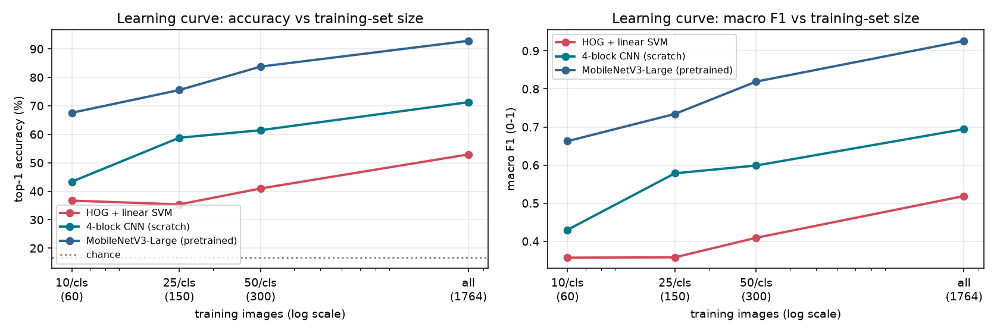

In [12]:
e3 = E.exp3_small_data()
display(pd.DataFrame(e3["runs"]).T[["method", "n_per_class", "n_train", "accuracy", "macro_f1", "train_time_min"]])
show("exp3_small_data.png")

## 8. Experiment 4 - efficiency (same CPU, batch size 1)


=== Experiment 4: efficiency ===
  HOG + linear SVM                          3.57 ms   0.000 M params     0.3 min train  size 0.26 MB
  HOG + colour hist. + SVM (variant)       13.63 ms   0.000 M params     0.5 min train  size 0.27 MB
  4-block CNN (scratch)                    16.82 ms   1.128 M params   100.8 min train  size 4.51 MB
  MobileNetV3-Large (pretrained)           29.07 ms   4.210 M params    44.8 min train  size 16.84 MB


,name,accuracy,macro_f1,runtime_ms_cpu,params_M,train_time_min,train_device,acc_per_ms,model_size_MB
A,HOG + linear SVM,52.925532,0.518723,3.574767,0.0,0.30889,cpu (NumPy),14.80531,0.260936
A+,HOG + colour hist. + SVM (variant),59.574468,0.586655,13.633327,0.0,0.476624,cpu (NumPy),4.369768,0.267076
B,4-block CNN (scratch),71.276596,0.694277,16.821225,1.128486,100.813591,cpu,4.237301,4.513944
C,MobileNetV3-Large (pretrained),92.819149,0.926127,29.074433,4.209718,44.797619,cpu,3.192466,16.838872


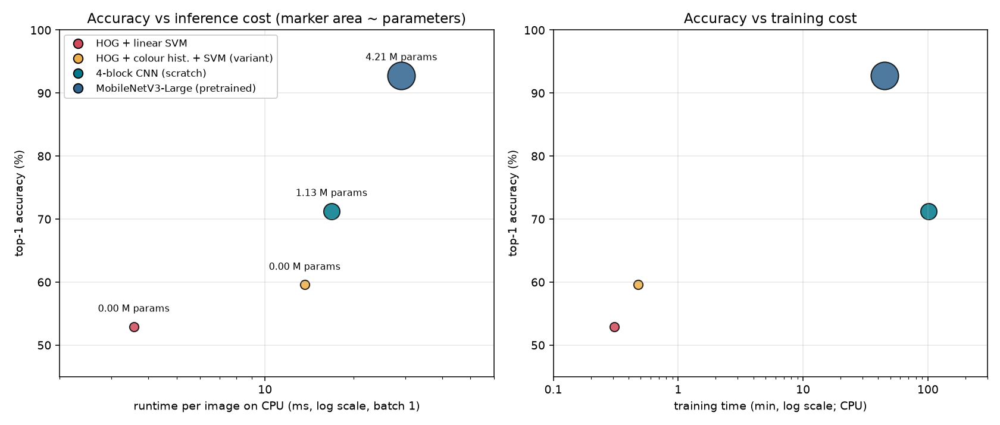

In [13]:
e4 = E.exp4_efficiency()
display(pd.DataFrame(e4).T)
show("exp4_efficiency.png")

## 9. Experiment 5 - error analysis


=== Experiment 5: error analysis ===
  HOG + linear SVM top confusions: glass->metal (15), plastic->cardboard (13), plastic->paper (10), glass->paper (10)
  4-block CNN (scratch) top confusions: plastic->glass (10), paper->trash (9), plastic->paper (8), paper->metal (8)
  MobileNetV3-Large (pretrained) top confusions: cardboard->paper (5), plastic->glass (4), glass->metal (4), glass->plastic (3)
  agreement: {'all_correct': 159, 'all_wrong': 13, 'only_C_correct': 57, 'C_wrong_but_B_or_A_right': 14, 'A_right_C_wrong': 6, 'n': 376}


{
 "top_confusions": {
  "A": [
   {
    "true": "glass",
    "pred": "metal",
    "count": 15
   },
   {
    "true": "plastic",
    "pred": "cardboard",
    "count": 13
   },
   {
    "true": "plastic",
    "pred": "paper",
    "count": 10
   },
   {
    "true": "glass",
    "pred": "paper",
    "count": 10
   },
   {
    "true": "plastic",
    "pred": "metal",
    "count": 9
   }
  ],
  "B": [
   {
    "true": "plastic",
    "pred": "glass",
    "count": 10
   },
   {
    "true": "paper",
    "pred": "trash",
    "count": 9
   },
   {
    "true": "plastic",
    "pred": "paper",
    "count": 8
   },
   {
    "true": "paper",
    "pred": "metal",
    "count": 8
   },
   {
    "true": "glass",
    "pred": "plastic",
    "count": 8
   }
  ],
  "C": [
   {
    "true": "cardboard",
    "pred": "paper",
    "count": 5
   },
   {
    "true": "plastic",
    "pred": "glass",
    "count": 4
   },
   {
    "true": "glass",
    "pred": "metal",
    "count": 4
   },
   {
    "true": "glass",
    "

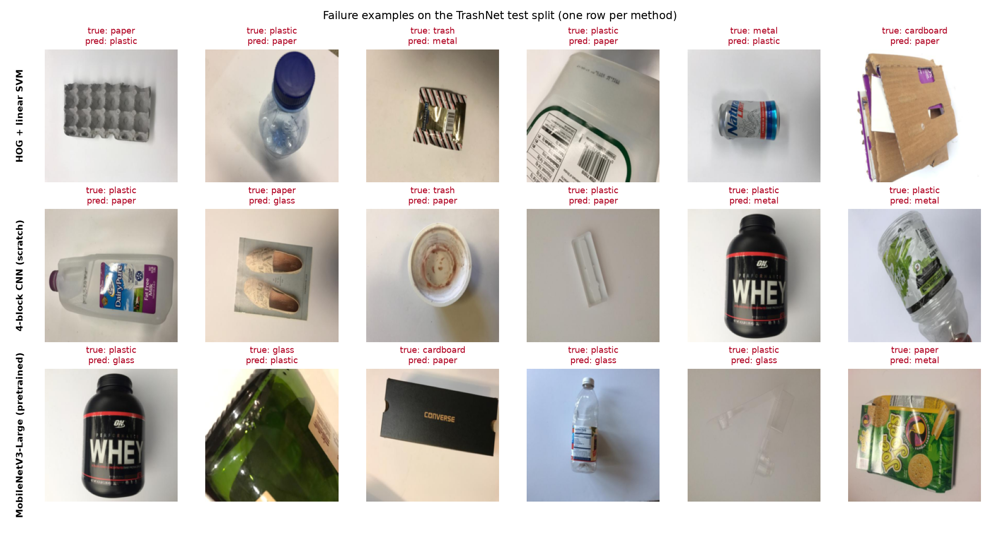

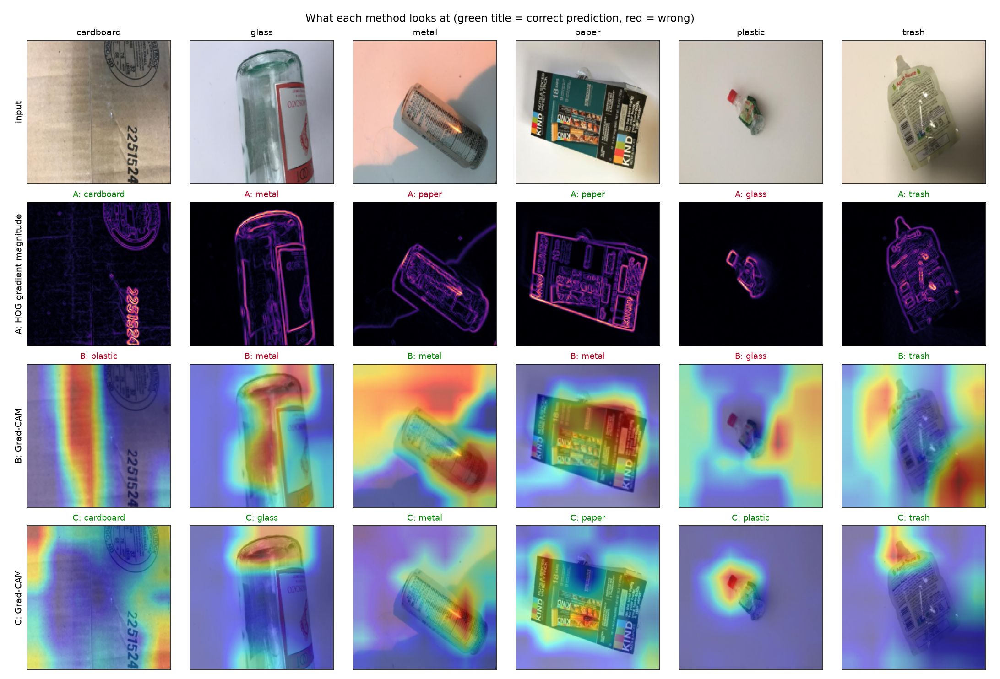

In [14]:
e5 = E.exp5_error_analysis(models)
print(json.dumps(e5, indent=1))
show("exp5_failures.png"); show("exp5_gradcam.png")

## 10. Experiment 6 - mixed-domain training (fixing the domain gap)
Experiment 2 showed a large accuracy drop on real-world photos. Here every method is retrained, with the
**same architecture and hyper-parameters**, on TrashNet train **plus** real-world web photos
(`src/prepare_mixed.py`: up to 300 train + 40 validation web photos per class; the 600 real-world test photos,
their near-duplicates and any near-copy of a TrashNet image are excluded). The **test sets are unchanged**.
A confidence threshold is calibrated on validation so that BIN says *"not sure"* instead of guessing.
These models are the ones used by the BIN app.

,candidates,unreadable,near_trashnet,near_realworld_test,usable,web_train,web_val
cardboard,791,0,403,2,386,300,40
glass,1916,0,474,19,1424,300,40
metal,669,0,410,4,255,215,40
paper,950,0,594,0,356,300,40
plastic,765,0,477,8,280,240,40
trash,597,0,0,22,575,300,40


,HOG + linear SVM,MobileNetV3-Large (pretrained),4-block CNN (scratch)
TrashNet test acc. (TrashNet-only model),52.93,92.82,71.28
TrashNet test acc. (mixed model),47.87,94.15,69.68
Real-world acc. (TrashNet-only model),9.33,62.83,36.17
Real-world acc. (mixed model),47.83,97.67,78.83
Real-world macro-F1 (mixed model),0.47,0.98,0.78
'Not sure' threshold,0.45,0.65,0.95
Real-world photos answered at threshold (%),4.17,94.00,20.83
Accuracy of those answers (%),88.00,99.47,98.40


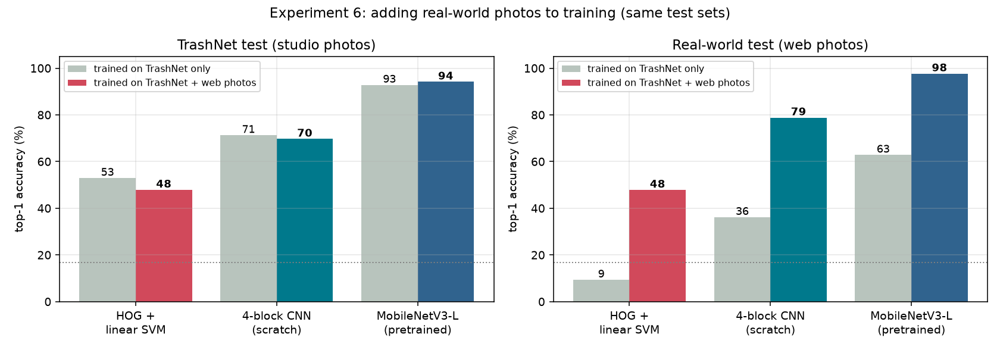

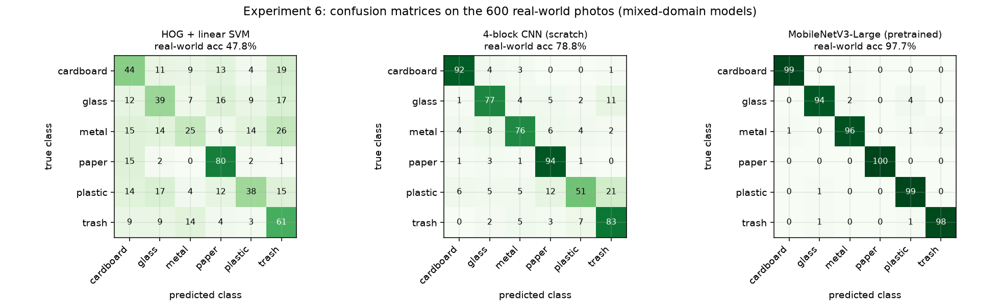

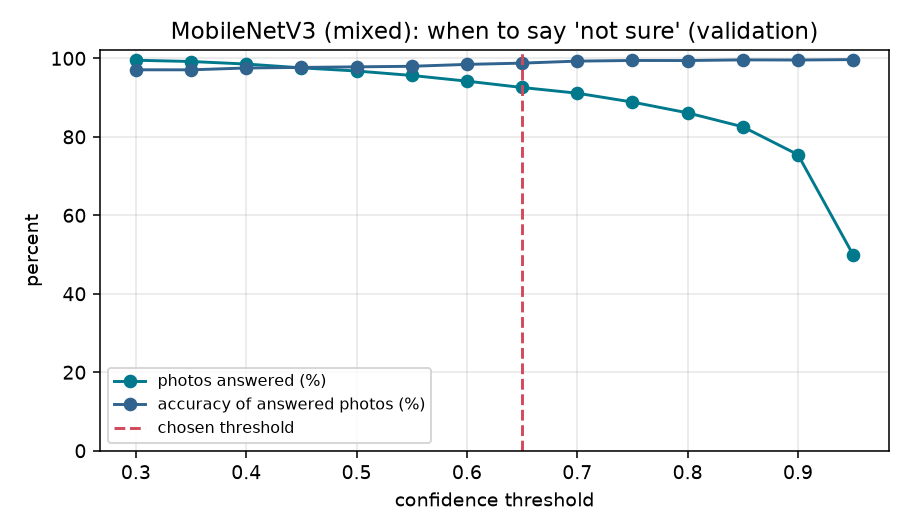

In [15]:
import prepare_mixed, mixed_domain
if need(prepare_mixed.MIXED_FILE):
    prepare_mixed.main()
mx = load_json(prepare_mixed.MIXED_FILE)
display(pd.DataFrame(mx["stats"]["per_class"]).T)
done6 = mixed_domain.OUT.exists() and all(k in load_json(mixed_domain.OUT)["methods"] for k in "ABC")
if RETRAIN or not done6:
    mixed_domain.main()    # resumes: methods already finished are skipped
e6 = load_json(mixed_domain.OUT)
mixed_domain.figures(e6)
display(pd.DataFrame({E.NAMES[k]: {
    "TrashNet test acc. (TrashNet-only model)": v["baseline_trashnet_only"]["trashnet_test_acc"],
    "TrashNet test acc. (mixed model)": v["trashnet_test"]["accuracy"],
    "Real-world acc. (TrashNet-only model)": v["baseline_trashnet_only"]["realworld_acc"],
    "Real-world acc. (mixed model)": v["realworld"]["accuracy"],
    "Real-world macro-F1 (mixed model)": v["realworld"]["macro_f1"],
    "'Not sure' threshold": v["threshold"]["threshold"],
    "Real-world photos answered at threshold (%)": 100 * v["realworld_at_threshold"]["coverage"],
    "Accuracy of those answers (%)": v["realworld_at_threshold"]["accuracy"]} for k, v in e6["methods"].items()}).round(2))
show("exp6_mixed_domain.png"); show("exp6_confusion_realworld.png"); show("exp6_confidence_threshold.png", 650)

## 11. The system: BIN
`src/system.py` runs the three methods, draws each label/confidence/runtime on the image and answers with the
recommended method - the one with the best macro-F1 on **real-world** photos - or says *"not sure"* below the
calibrated threshold. It is used by the desktop/Colab app `app/app.py` (Gradio). The **phone app** in `web/`
(https://karlsxo.github.io/Computer-Vison---Final-Project/) runs the same models on the phone; `tools/verify_web.py`
checks that its predictions agree with Python. Below, the system is run on photos it has never seen.

models: mixed | answers with: MobileNetV3-Large | not-sure threshold: 0.65


**MobileNetV3-Large** gives BIN's answer because it is the most accurate on unseen real-world photos (97.7% vs 47.8% for HOG + linear SVM, 78.8% for 4-block CNN (scratch)) and reaches 94.1% on the TrashNet test photos. It runs in about 38 ms per image on a laptop CPU with 4.2 M parameters. Models trained on: TrashNet + real-world web photos.

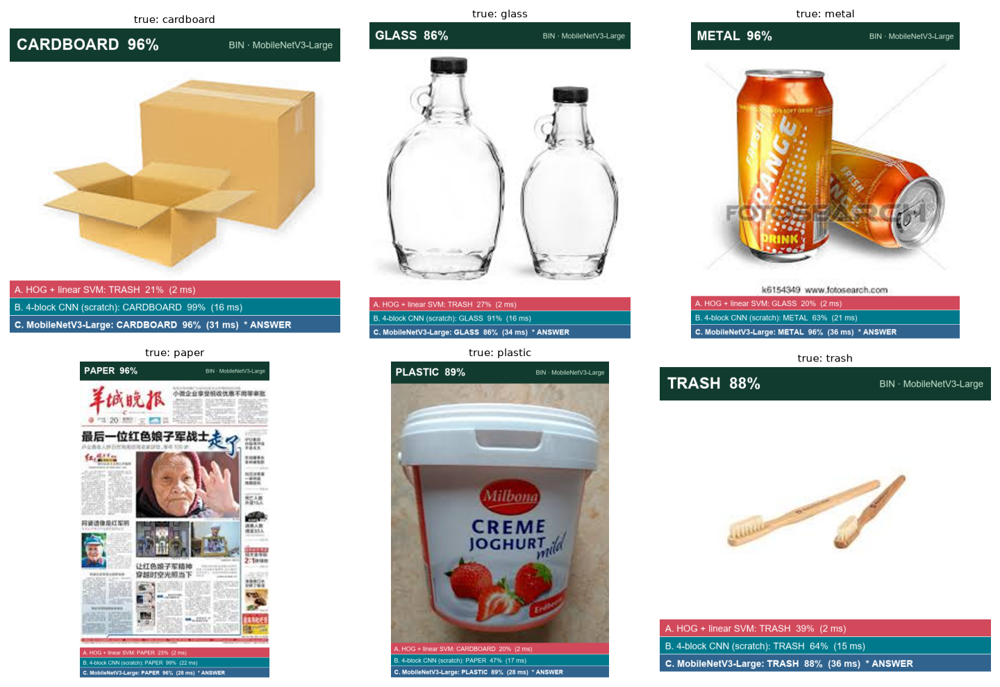

In [16]:
from system import BinSystem, METHOD_NAMES
sorter = BinSystem()
print("models:", sorter.source, "| answers with:", METHOD_NAMES[sorter.recommended], "| not-sure threshold:", sorter.threshold)
display(Markdown(sorter.reason))
demo_items = (own_photo_items()[:3] or []) + load_realworld()[::100][:6 - min(3, len(own_photo_items()))]
fig, axes = plt.subplots(2, 3, figsize=(16, 11))
for ax, (p, y) in zip(axes.ravel(), demo_items):
    img = load_rgb(p); preds = sorter.predict(img)
    ax.imshow(sorter.annotate(img, preds)); ax.set_title(f"true: {CLASSES[y]}"); ax.axis("off")
plt.tight_layout(); fig.savefig(FIG_DIR / "system_demo.png", dpi=90); plt.close(fig)
show("system_demo.png")

In [17]:
LAUNCH_APP = False   # set True to start the web app (in Colab a public *.gradio.live link is printed)
if LAUNCH_APP:
    sys.path.insert(0, str(PROJECT / "app"))
    import app as webapp
    webapp.build_ui().launch(share=IN_COLAB)

In [18]:
# Phone app check (results/web_verification.json, produced by tools/verify_web.py in a headless browser)
wv = RESULTS_DIR / "web_verification.json"
if wv.exists():
    v = load_json(wv)
    display(pd.DataFrame({f"{s} / {k}": m for s, d in v["sets"].items() for k, m in d.items()}).T)

,agreement_with_python_%,phone_accuracy_%,python_accuracy_%,ms_per_image_desktop_browser
trashnet_test / A,100.00,47.87,47.87,2.7
trashnet_test / B,100.00,69.68,69.68,83.3
trashnet_test / C,100.00,94.15,94.15,47.7
realworld / A,99.83,47.83,47.83,2.8
realworld / B,100.00,78.83,78.83,63.0
realworld / C,100.00,97.67,97.67,52.9


## 12. Answer to the research question
The discussion below is filled from the measured numbers (see `docs/` and the report for the full analysis).

In [19]:
s = {k: e1["methods"][k] for k in ["A", "B", "C"]}
rw = e2["results"]["realworld"]
best = max(s, key=lambda k: s[k]["macro_f1"])
lines = [f"* **Best method:** {E.NAMES[best]} - test accuracy {s[best]['accuracy']:.1f}% "
         f"(95% CI {s[best]['acc_ci95'][0]:.1f}-{s[best]['acc_ci95'][1]:.1f}), macro-F1 {s[best]['macro_f1']:.3f}."]
for k in ["A", "B", "C"]:
    lines.append(f"* {E.NAMES[k]}: {s[k]['accuracy']:.1f}% on TrashNet test -> {rw[k]['accuracy']:.1f}% "
                 f"on real-world photos (drop {rw[k]['acc_drop_pts']:.1f} points, keeps "
                 f"{rw[k]['relative_retention'] * 100:.0f}% of its accuracy).")
small = e3["runs"]
lines.append("* With only 10 images per class: " + ", ".join(
    f"{E.NAMES[k]} {small[f'{k}_10']['accuracy']:.1f}%" for k in ["A", "B", "C"]) + ".")
lines.append("* Adding real-world photos to training (Experiment 6) raises real-world accuracy to " + ", ".join(
    f"{E.NAMES[k]} {e6['methods'][k]['realworld']['accuracy']:.1f}%" for k in ["A", "B", "C"])
    + f"; BIN answers with {METHOD_NAMES[sorter.recommended]}.")
display(Markdown("\n".join(lines)))

* **Best method:** MobileNetV3-Large (pretrained) - test accuracy 92.8% (95% CI 90.2-95.2), macro-F1 0.926.
* HOG + linear SVM: 52.9% on TrashNet test -> 9.3% on real-world photos (drop 43.6 points, keeps 18% of its accuracy).
* 4-block CNN (scratch): 71.3% on TrashNet test -> 36.2% on real-world photos (drop 35.1 points, keeps 51% of its accuracy).
* MobileNetV3-Large (pretrained): 92.8% on TrashNet test -> 62.8% on real-world photos (drop 30.0 points, keeps 68% of its accuracy).
* With only 10 images per class: HOG + linear SVM 36.7%, 4-block CNN (scratch) 43.4%, MobileNetV3-Large (pretrained) 67.6%.
* Adding real-world photos to training (Experiment 6) raises real-world accuracy to HOG + linear SVM 47.8%, 4-block CNN (scratch) 78.8%, MobileNetV3-Large (pretrained) 97.7%; BIN answers with MobileNetV3-Large.